<a href="https://colab.research.google.com/github/emnark/GROUP22_CENG313/blob/main/assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os

os.environ['KAGGLE_USERNAME'] = "emnark"
os.environ['KAGGLE_KEY'] = "3d031e2435cd0b22708cb965d0ed4298"

!kaggle competitions files -c birdclef-2025
!kaggle competitions download -c birdclef-2025 -f train.csv
!kaggle competitions download -c birdclef-2025 -f taxonomy.csv




Next Page Token = CfDJ8CXkJvnxKG5Ktgac76JjV5FvbcGjmxrrmSQHe3_IT5iVvB4CKxkBCCqtQRo0eKOsHg5m3B84yPLF3Pp43pewaxwOyPldqlp93YSTM0E6TCYqBrYyw4zZbm-uxwqkLZWlC1gYFCl8NRXZxzjDbAiqpS24qgeRp8ZnNUMM
name                                      size  creationDate                
----------------------------------  ----------  --------------------------  
recording_location.txt                     232  2025-03-10 16:57:13.159000  
sample_submission.csv                    15191  2025-03-10 16:57:13.162000  
taxonomy.csv                             12272  2025-03-10 16:57:13.159000  
test_soundscapes/readme.txt                 83  2025-03-10 16:57:13.159000  
train.csv                              4998282  2025-03-10 16:57:13.209000  
train_audio/1139490/CSA36385.ogg        770871  2025-03-10 16:57:47.042000  
train_audio/1139490/CSA36389.ogg        755101  2025-03-10 16:57:47.001000  
train_audio/1192948/CSA36358.ogg        902788  2025-03-10 16:57:53.829000  
train_audio/1192948/CSA36366.ogg        823

Train Veri Boyutu: (28564, 13)

İlk 5 Satır:


,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
0,1139490,[''],[''],1139490/CSA36385.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
1,1139490,[''],[''],1139490/CSA36389.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
2,1192948,[''],[''],1192948/CSA36358.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
3,1192948,[''],[''],1192948/CSA36366.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.2800,-73.8582,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
4,1192948,[''],[''],1192948/CSA36373.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0



Veri Tipleri ve Eksik Değerler:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28564 entries, 0 to 28563
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   primary_label     28564 non-null  object 
 1   secondary_labels  28564 non-null  object 
 2   type              28564 non-null  object 
 3   filename          28564 non-null  object 
 4   collection        28564 non-null  object 
 5   rating            28564 non-null  float64
 6   url               28564 non-null  object 
 7   latitude          27755 non-null  float64
 8   longitude         27755 non-null  float64
 9   scientific_name   28564 non-null  object 
 10  common_name       28564 non-null  object 
 11  author            28564 non-null  object 
 12  license           28564 non-null  object 
dtypes: float64(3), object(10)
memory usage: 2.8+ MB
None


/tmp/ipykernel_714/2495435122.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15.values, y=top15.index, palette='crest')


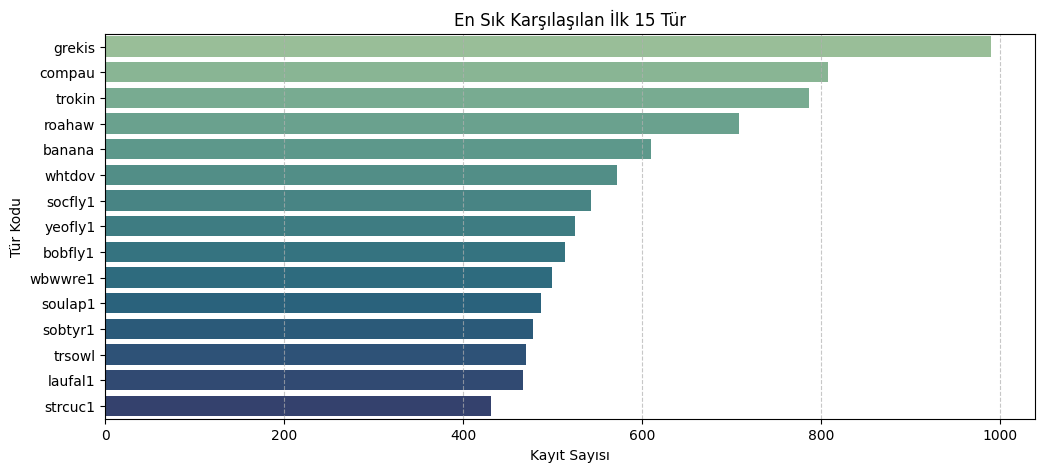

/tmp/ipykernel_714/2495435122.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_train, x='rating', palette='magma')


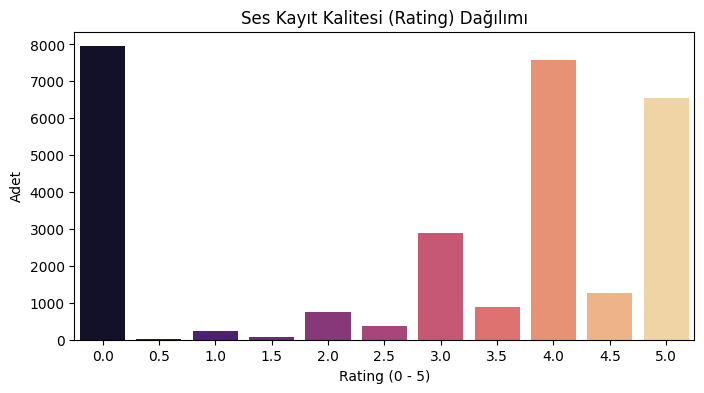

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tabloları okuma
df_train = pd.read_csv('train.csv')
df_tax = pd.read_csv('taxonomy.csv')

print("Train Veri Boyutu:", df_train.shape)
print("\nİlk 5 Satır:")
display(df_train.head())

print("\nVeri Tipleri ve Eksik Değerler:")
print(df_train.info())

# 1. En çok ve en az kaydı bulunan türler
plt.figure(figsize=(12, 5))
top15 = df_train['primary_label'].value_counts().head(15)
sns.barplot(x=top15.values, y=top15.index, palette='crest')
plt.title('En Sık Karşılaşılan İlk 15 Tür')
plt.xlabel('Kayıt Sayısı')
plt.ylabel('Tür Kodu')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# 2. Kayıt derecelendirme (rating) kalitesi dağılımı
plt.figure(figsize=(8, 4))
sns.countplot(data=df_train, x='rating', palette='magma')
plt.title('Ses Kayıt Kalitesi (Rating) Dağılımı')
plt.xlabel('Rating (0 - 5)')
plt.ylabel('Adet')
plt.show()


In [6]:
# Listelenen dosyalardan örnek 1 adet ses kaydı indirme
!kaggle competitions download -c birdclef-2025 -f train_audio/1139490/CSA36385.ogg
!mkdir -p sample_audio
!mv CSA36385.ogg sample_audio/


100% 753k/753k [00:00<00:00, 115MB/s]



Örnekleme Hızı (Sampling Rate): 32000 Hz
Toplam Süre: 98.85 saniye


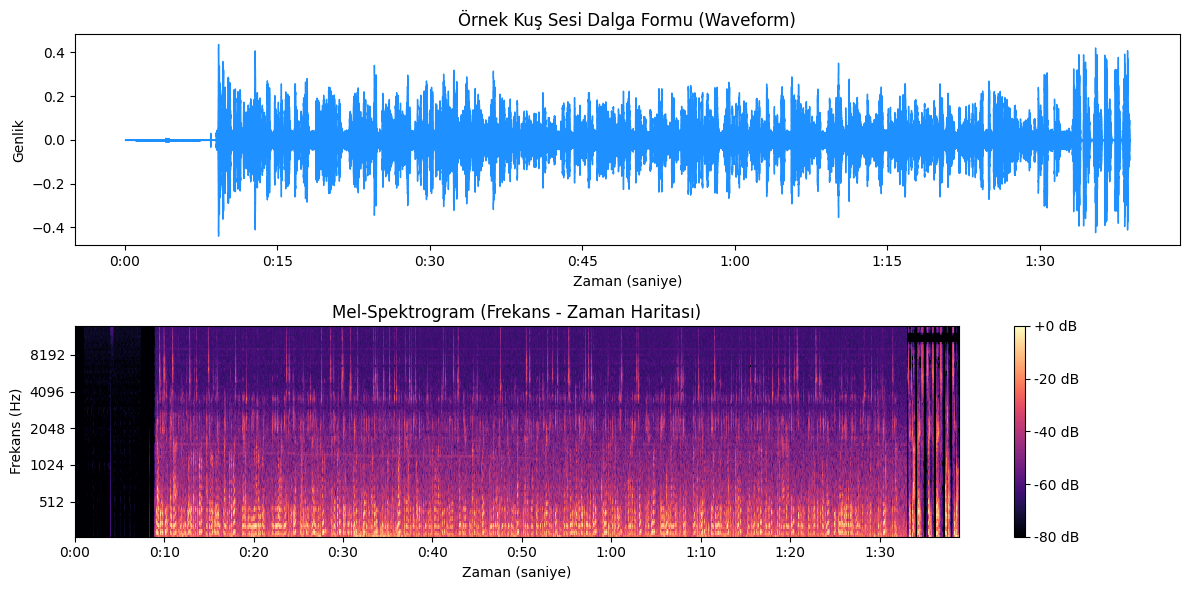

In [7]:
import librosa
import librosa.display
import numpy as np

audio_path = 'sample_audio/CSA36385.ogg'

# Sesi 32 kHz standart örnekleme frekansıyla (BirdCLEF standardı)yükleme
y, sr = librosa.load(audio_path, sr=32000)

print(f"Örnekleme Hızı (Sampling Rate): {sr} Hz")
print(f"Toplam Süre: {len(y)/sr:.2f} saniye")

# 1. Dalga Formu (Waveform)
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr, color='dodgerblue')
plt.title('Örnek Kuş Sesi Dalga Formu (Waveform)')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Genlik')

# 2. Mel-Spektrogram Hesabı ve Görselleştirilmesi
melspec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmin=50, fmax=14000)
melspec_db = librosa.power_to_db(melspec, ref=np.max)

plt.subplot(2, 1, 2)
librosa.display.specshow(melspec_db, sr=sr, x_axis='time', y_axis='mel', fmin=50, fmax=14000, cmap='magma')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel-Spektrogram (Frekans - Zaman Haritası)')
plt.xlabel('Zaman (saniye)')
plt.ylabel('Frekans (Hz)')

plt.tight_layout()
plt.show()


In [9]:
import os

# src klasörünü Colab içinde oluşturma
os.makedirs('src', exist_ok=True)

# 1. Ses yükleme ve spektrogram fonksiyonunu src/data.py dosyasına kaydetme
data_py_content = """import librosa
import numpy as np

def load_audio(path, sr=32000):
    y, _ = librosa.load(path, sr=sr)
    return y, sr

def compute_melspec(y, sr=32000, n_mels=128, fmin=50, fmax=14000):
    melspec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels, fmin=fmin, fmax=fmax)
    return librosa.power_to_db(melspec, ref=np.max)

def extract_features(y, sr=32000):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    return np.mean(mfcc, axis=1)
"""

with open('src/data.py', 'w') as f:
    f.write(data_py_content)

# 2. Baseline model sınıfını src/models.py dosyasına kaydetme
models_py_content = """from sklearn.ensemble import RandomForestClassifier

def get_baseline_model():
    return RandomForestClassifier(n_estimators=100, random_state=42)
"""

with open('src/models.py', 'w') as f:
    f.write(models_py_content)

print("src/ modülleri başarıyla güncellendi!")


src/ modülleri başarıyla güncellendi!


In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier

# Metadata üzerinden örnekleme
top5_species = df_train['primary_label'].value_counts().head(5).index.tolist()
df_subset = df_train[df_train['primary_label'].isin(top5_species)].copy()

# Baseline öznitelikleri (Latitude, Longitude, Rating)
features = ['latitude', 'longitude', 'rating']
df_subset = df_subset.dropna(subset=features)

X = df_subset[features]
y = df_subset['primary_label']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Modeli eğitme
baseline_rf = RandomForestClassifier(n_estimators=100, random_state=42)
baseline_rf.fit(X_train, y_train)

# Tahmin ve Metrikler
y_pred = baseline_rf.predict(X_val)
y_proba = baseline_rf.predict_proba(X_val)

print("--- Baseline Model Classification Report ---")
print(classification_report(y_val, y_pred))

# Macro ROC-AUC Skoru (Yarışma Metriği)
y_val_bin = label_binarize(y_val, classes=baseline_rf.classes_)
macro_auc = roc_auc_score(y_val_bin, y_proba, multi_class='ovr', average='macro')
print(f"Validation Macro ROC-AUC Skoru: {macro_auc:.4f}")


--- Baseline Model Classification Report ---
              precision    recall  f1-score   support

      banana       0.53      0.56      0.55       117
      compau       0.45      0.44      0.44       161
      grekis       0.45      0.49      0.47       195
      roahaw       0.44      0.38      0.41       136
      trokin       0.52      0.50      0.51       155

    accuracy                           0.48       764
   macro avg       0.48      0.48      0.48       764
weighted avg       0.47      0.48      0.47       764

Validation Macro ROC-AUC Skoru: 0.7599
